In [5]:
%pip install pandas numpy matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.8 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.8 MB ? eta -:--:--
   - -----------------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Walmart_Sales.csv")

In [2]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Unnamed: 8,Unnamed: 9
0,1,05/02/2010 00:00,1643690.90,0,42.31,2.572,211.096358,8.106,NaN,#NAME?
1,1,12/02/2010 00:00,1641957.44,1,38.51,2.548,211.242170,8.106,NaN,NaN
2,1,19/02/2010 00:00,1611968.17,0,39.93,2.514,211.289143,8.106,NaN,NaN
3,1,26/02/2010 00:00,1409727.59,0,46.63,2.561,211.319643,8.106,NaN,0
4,1,05/03/2010 00:00,1554806.68,0,46.50,2.625,211.350143,8.106,NaN,0


In [3]:
df.shape

(6435, 10)

In [4]:
df.columns

Index(['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
       'Fuel_Price', 'CPI', 'Unemployment', 'Unnamed: 8', 'Unnamed: 9'],
      dtype='str')

In [5]:
df.describe()

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Unnamed: 8
count,6435.000000,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000,0.0
mean,23.000000,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151,NaN
std,12.988182,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885,NaN
min,1.000000,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000,NaN
25%,12.000000,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000,NaN
50%,23.000000,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000,NaN
75%,34.000000,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000,NaN
max,45.000000,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000,NaN


In [6]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

In [7]:
df["Year"] = df["Date"].dt.year

In [8]:
df["Month"] = df["Date"].dt.month

In [9]:
df["Month_Name"] = df["Date"].dt.month_name()


In [10]:
df["Quarter"] = df["Date"].dt.quarter

In [11]:
df["Holiday_Status"] = np.where(
    df["Holiday_Flag"] == 1,
    "Holiday",
    "Non-Holiday"
)

In [12]:
total_sales = df["Weekly_Sales"].sum()

average_sales = df["Weekly_Sales"].mean()

highest_sales = df["Weekly_Sales"].max()

lowest_sales = df["Weekly_Sales"].min()

number_of_stores = df["Store"].nunique()

number_of_weeks = df["Date"].nunique()

In [13]:
print("Total Sales:", total_sales)
print("Average Weekly Sales:", average_sales)
print("Highest Weekly Sales:", highest_sales)
print("Lowest Weekly Sales:", lowest_sales)
print("Number of Stores:", number_of_stores)
print("Number of Weeks:", number_of_weeks)

Total Sales: 6737218987.11
Average Weekly Sales: 1046964.8775617715
Highest Weekly Sales: 3818686.45
Lowest Weekly Sales: 209986.25
Number of Stores: 45
Number of Weeks: 143


In [14]:
sales_by_store = (
    df.groupby("Store")["Weekly_Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(sales_by_store)

Store
20    3.013978e+08
4     2.995440e+08
14    2.889999e+08
13    2.865177e+08
2     2.753824e+08
10    2.716177e+08
27    2.538559e+08
6     2.237561e+08
1     2.224028e+08
39    2.074455e+08
19    2.066349e+08
31    1.996139e+08
23    1.987506e+08
24    1.940160e+08
11    1.939628e+08
28    1.892637e+08
41    1.813419e+08
32    1.668192e+08
18    1.551147e+08
22    1.470756e+08
12    1.442872e+08
26    1.434164e+08
34    1.382498e+08
40    1.378703e+08
35    1.315207e+08
8     1.299512e+08
17    1.277821e+08
45    1.123953e+08
21    1.081179e+08
25    1.010612e+08
43    9.056544e+07
15    8.913368e+07
7     8.159828e+07
42    7.956575e+07
9     7.778922e+07
29    7.714155e+07
16    7.425243e+07
37    7.420274e+07
30    6.271689e+07
3     5.758674e+07
38    5.515963e+07
36    5.341221e+07
5     4.547569e+07
44    4.329309e+07
33    3.716022e+07
Name: Weekly_Sales, dtype: float64


In [15]:
top_10 = sales_by_store.head(10)

print(top_10)

Store
20    3.013978e+08
4     2.995440e+08
14    2.889999e+08
13    2.865177e+08
2     2.753824e+08
10    2.716177e+08
27    2.538559e+08
6     2.237561e+08
1     2.224028e+08
39    2.074455e+08
Name: Weekly_Sales, dtype: float64


In [16]:
bottom_10 = sales_by_store.tail(10)

print(bottom_10)

Store
29    77141554.31
16    74252425.40
37    74202740.32
30    62716885.12
3     57586735.07
38    55159626.42
36    53412214.97
5     45475688.90
44    43293087.84
33    37160221.96
Name: Weekly_Sales, dtype: float64


In [17]:
sales_by_year = (
    df.groupby("Year")["Weekly_Sales"]
    .sum()
)

print(sales_by_year)

Year
2010    2.288886e+09
2011    2.448200e+09
2012    2.000133e+09
Name: Weekly_Sales, dtype: float64


In [18]:
sales_by_month = (
    df.groupby("Month")["Weekly_Sales"]
    .sum()
)

print(sales_by_month)

Month
1     3.325984e+08
2     5.687279e+08
3     5.927859e+08
4     6.468598e+08
5     5.571256e+08
6     6.226299e+08
7     6.500010e+08
8     6.130902e+08
9     5.787612e+08
10    5.847848e+08
11    4.130157e+08
12    5.768386e+08
Name: Weekly_Sales, dtype: float64


In [19]:
holiday_analysis = (
    df.groupby("Holiday_Status")["Weekly_Sales"]
    .agg(["sum", "mean", "count"])
)

print(holiday_analysis)

                         sum          mean  count
Holiday_Status                                   
Holiday         5.052996e+08  1.122888e+06    450
Non-Holiday     6.231919e+09  1.041256e+06   5985


In [20]:
correlation = df[
    [
        "Weekly_Sales",
        "Temperature",
        "Fuel_Price",
        "CPI",
        "Unemployment"
    ]
].corr()

print(correlation)

              Weekly_Sales  Temperature  Fuel_Price       CPI  Unemployment
Weekly_Sales      1.000000    -0.063810    0.009464 -0.072634     -0.106176
Temperature      -0.063810     1.000000    0.144982  0.176888      0.101158
Fuel_Price        0.009464     0.144982    1.000000 -0.170642     -0.034684
CPI              -0.072634     0.176888   -0.170642  1.000000     -0.302020
Unemployment     -0.106176     0.101158   -0.034684 -0.302020      1.000000


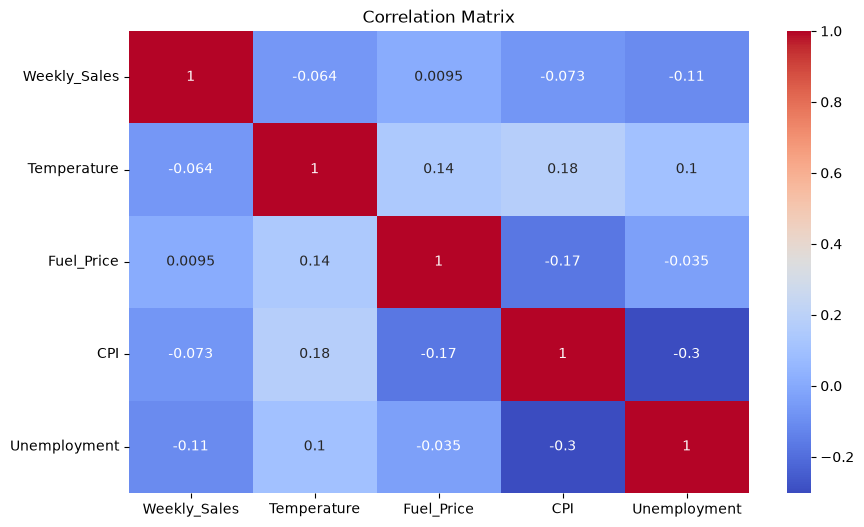

In [22]:
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

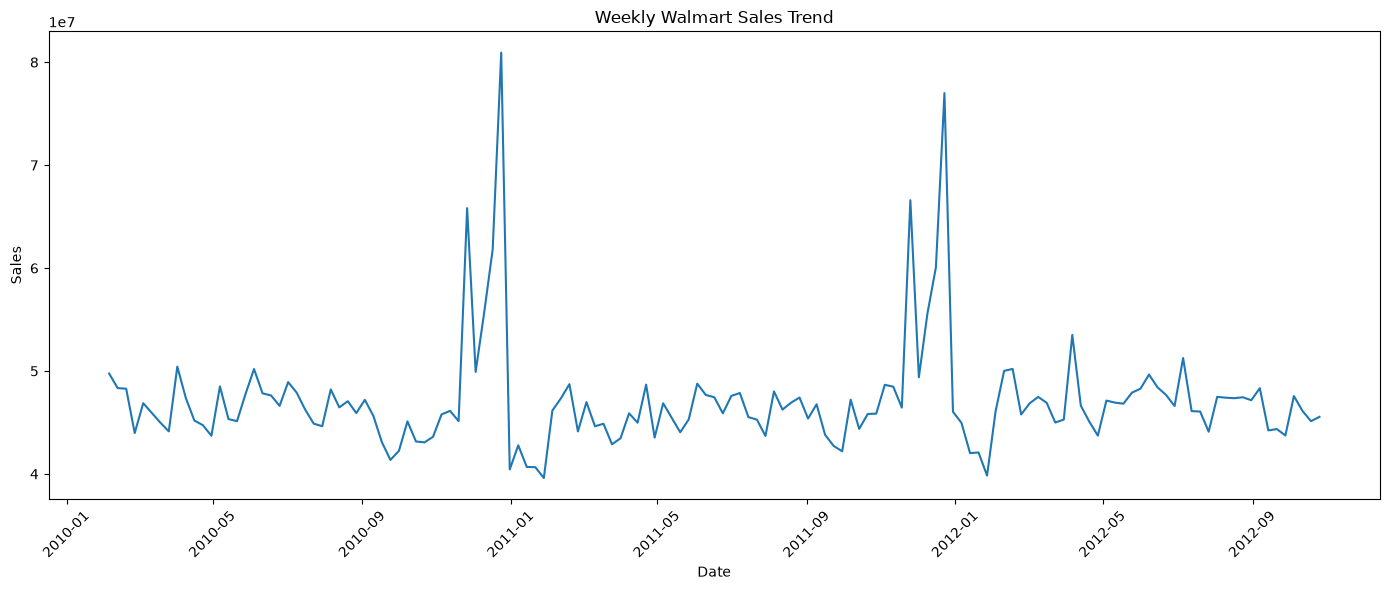

In [23]:
daily_sales = (
    df.groupby("Date")["Weekly_Sales"]
    .sum()
)

plt.figure(figsize=(14, 6))

plt.plot(
    daily_sales.index,
    daily_sales.values
)

plt.title("Weekly Walmart Sales Trend")

plt.xlabel("Date")

plt.ylabel("Sales")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

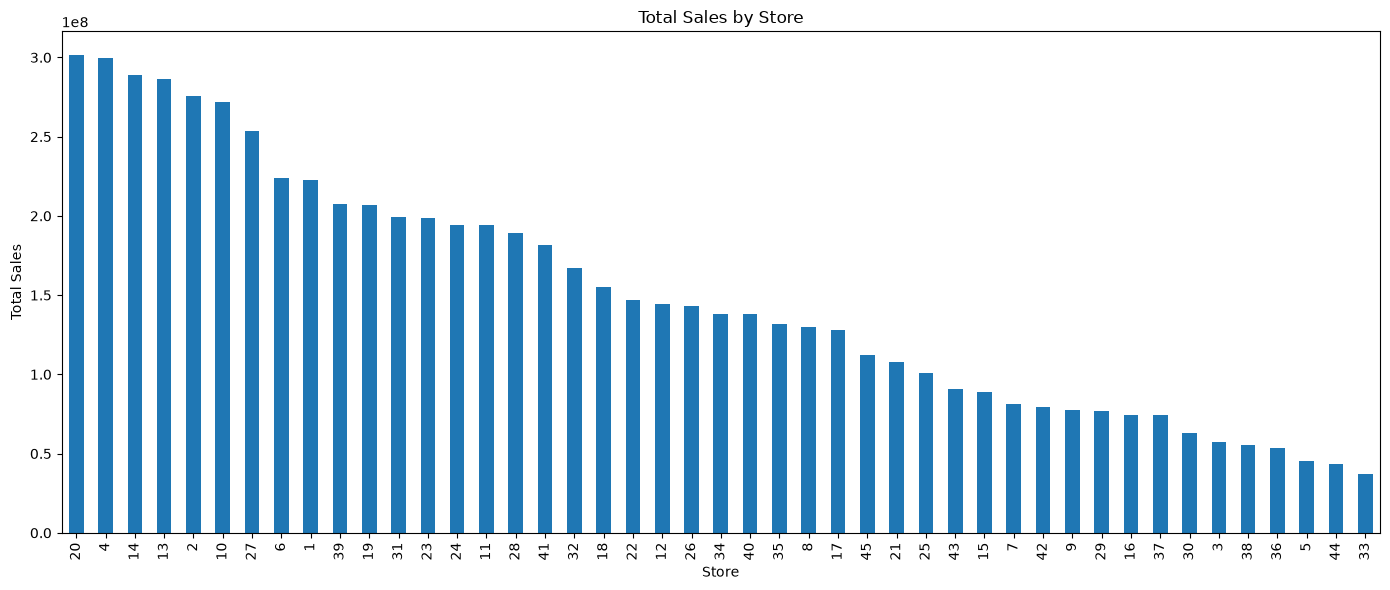

In [24]:
plt.figure(figsize=(14, 6))

sales_by_store.plot(kind="bar")

plt.title("Total Sales by Store")

plt.xlabel("Store")

plt.ylabel("Total Sales")

plt.tight_layout()

plt.show()

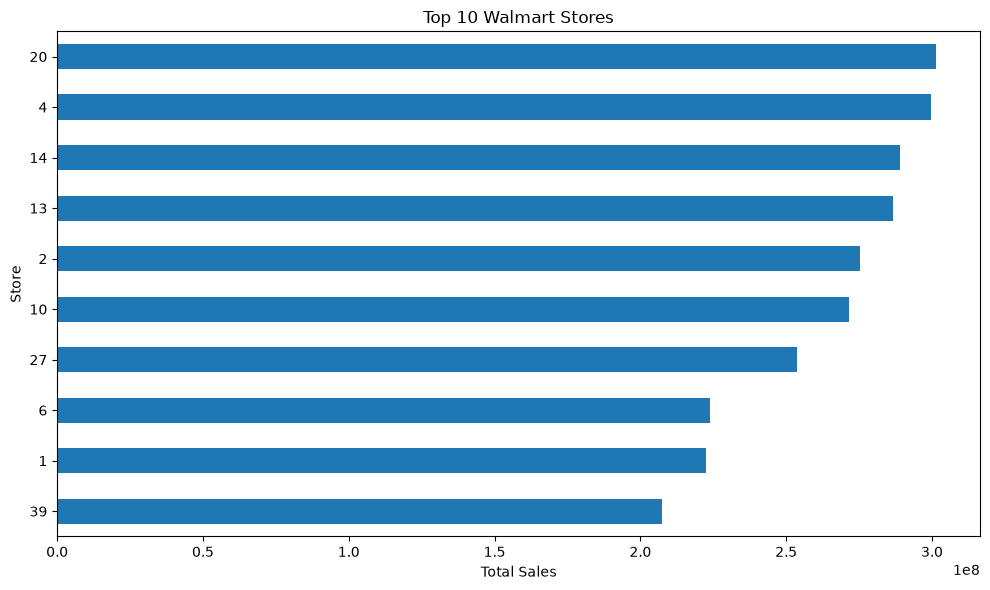

In [25]:
plt.figure(figsize=(10, 6))

top_10.sort_values().plot(kind="barh")

plt.title("Top 10 Walmart Stores")

plt.xlabel("Total Sales")

plt.ylabel("Store")

plt.tight_layout()

plt.show()

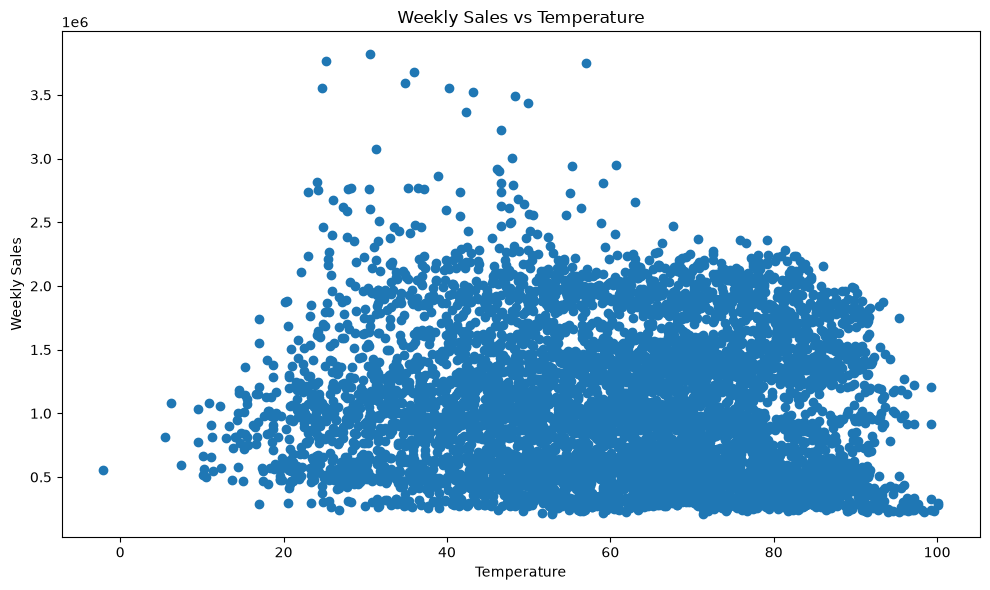

In [26]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Temperature"],
    df["Weekly_Sales"]
)

plt.title("Weekly Sales vs Temperature")

plt.xlabel("Temperature")

plt.ylabel("Weekly Sales")

plt.tight_layout()

plt.show()

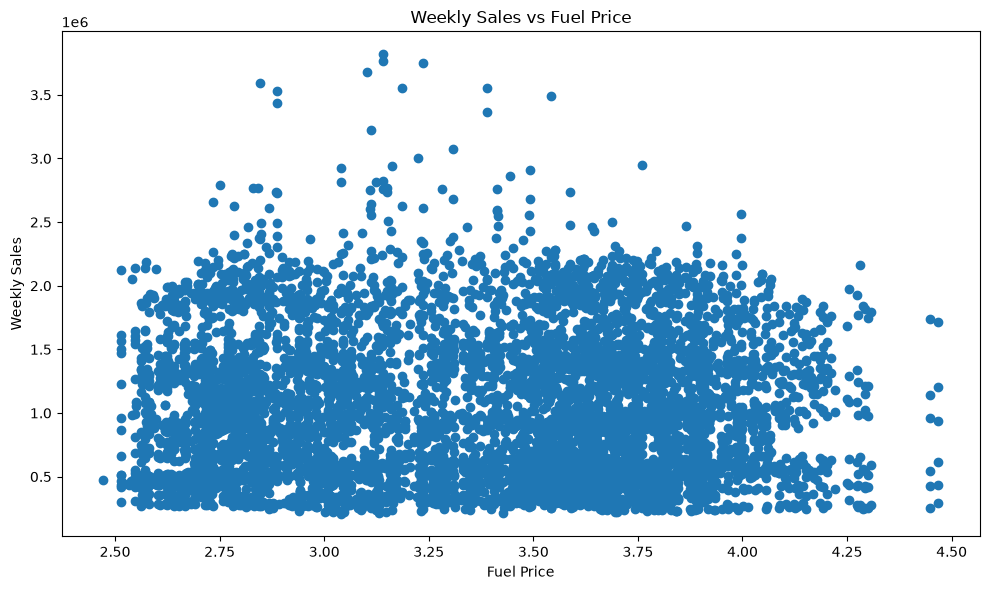

In [27]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Fuel_Price"],
    df["Weekly_Sales"]
)

plt.title("Weekly Sales vs Fuel Price")

plt.xlabel("Fuel Price")

plt.ylabel("Weekly Sales")

plt.tight_layout()

plt.show()

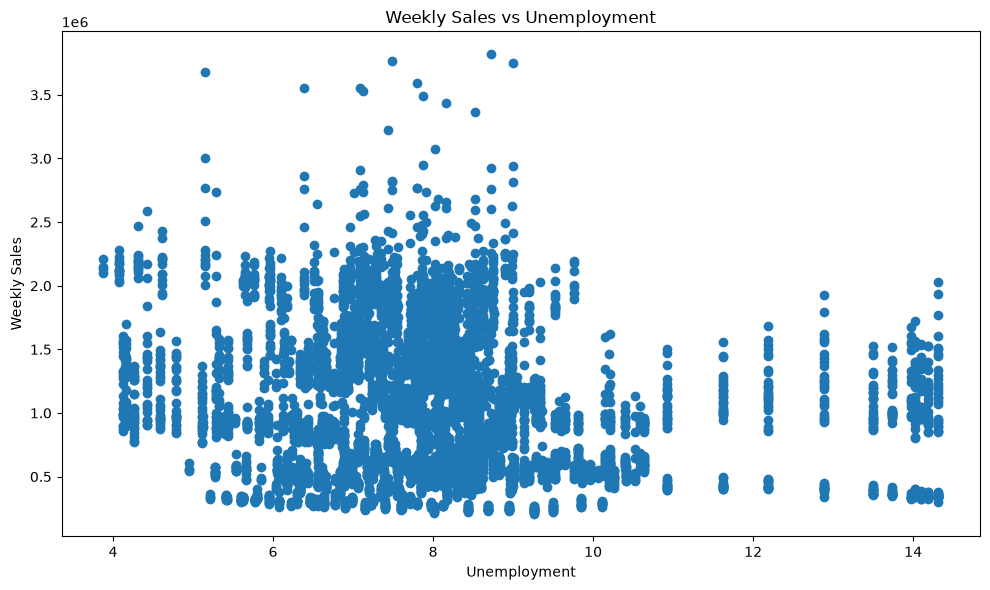

In [28]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Unemployment"],
    df["Weekly_Sales"]
)

plt.title("Weekly Sales vs Unemployment")

plt.xlabel("Unemployment")

plt.ylabel("Weekly Sales")

plt.tight_layout()

plt.show()